# Phase 2: Model Comparison

This notebook validates baseline predictive models for cardiac risk prediction, serving as the foundation for the explainability/counterfactual search. Models are trained on a stratified train/test split from `PERIOD == 1`.

In [11]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import k_fold_cross_validation
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, brier_score_loss, average_precision_score, precision_recall_curve
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings

# Suppress annoying LightGBM feature name warnings since we use numpy arrays or wrap in CalibratedClassifierCV
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

from src.data_pipeline import load_and_preprocess_data

# Set global seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)


In [12]:
# Load preprocessed, imputed, and scaled data
train_df, test_df, imm_feats, dir_feats, act_feats = load_and_preprocess_data(filepath="../data/frmgham2.csv", random_seed=RANDOM_SEED)

feature_cols = imm_feats + dir_feats + act_feats
print(f"Total features: {len(feature_cols)}")


Loading data from ../data/frmgham2.csv...

Missingness before imputation (%):
BMI           0.448113
RANDID        0.000000
educ          2.476415
SYSBP         0.000000
TOTCHOL       1.179245
CIGPDAY       0.683962
PREVCHD       0.000000
AGE           0.000000
PREVMI        0.000000
GLUCOSE       9.150943
PREVAP        0.000000
ANYCHD        0.000000
DIABP         0.000000
HEARTRTE      0.023585
CURSMOKE      0.000000
TIMECHD       0.000000
PREVSTRK      0.000000
SEX           0.000000
BPMEDS        1.250000
PREVHYP       0.000000
time_years    0.000000
DIABETES      0.000000
dtype: float64

--- Imputation Impact (Train Set) ---
AGE: mean shift=0.00%, var shift=0.00%
TOTCHOL: mean shift=0.01%, var shift=1.14%
SYSBP: mean shift=0.00%, var shift=0.00%
DIABP: mean shift=0.00%, var shift=0.00%
CIGPDAY: mean shift=0.65%, var shift=0.28%
BMI: mean shift=0.01%, var shift=0.47%
HEARTRTE: mean shift=0.00%, var shift=0.03%
GLUCOSE: mean shift=0.41%, var shift=9.11%
SEX: mean shift=0.00%, var sh

## 1. Cox Proportional Hazards Model (`lifelines`)
**Why this model was included**: The Cox Proportional Hazards model is the standard for survival analysis in clinical literature. It provides an interpretable baseline, natively handles right-censoring, and estimates hazard ratios. We use it to predict the *survival trajectory* (time to ANYCHD) over 10 years, which will be the primary target for our Phase 4 counterfactual search.


In [13]:
# Train CoxPHFitter
cox_train = train_df[feature_cols + ['time_years', 'ANYCHD']].copy()
cox_test = test_df[feature_cols + ['time_years', 'ANYCHD']].copy()

# Preemptively check for low variance and multicollinearity to prevent ConvergenceError
# We use a COPY of feature_cols specifically for Cox, to avoid stripping these from DNN/Trees
cox_feature_cols = feature_cols.copy()
X_cox = cox_train[cox_feature_cols]

# 1. Drop features with near-zero variance
variances = X_cox.var()
low_var_cols = variances[variances < 1e-4].index.tolist()
if low_var_cols:
    print(f"Dropping low variance features for Cox: {low_var_cols}")
    cox_feature_cols = [c for c in cox_feature_cols if c not in low_var_cols]
    X_cox = cox_train[cox_feature_cols]

# 2. Check VIF and drop highly collinear features (VIF > 10)
vif_data = pd.DataFrame()
vif_data["feature"] = X_cox.columns
vif_data["VIF"] = [variance_inflation_factor(X_cox.values, i) for i in range(len(X_cox.columns))]
high_vif = vif_data[vif_data["VIF"] > 10]["feature"].tolist()
if high_vif:
    print(f"Dropping high VIF features for Cox: {high_vif}")
    cox_feature_cols = [c for c in cox_feature_cols if c not in high_vif]
    X_cox = cox_train[cox_feature_cols]

print(f"Features used for Cox model: {cox_feature_cols}")

cph = CoxPHFitter(penalizer=0.1) # Increased L2 penalty for stability
cph.fit(cox_train[cox_feature_cols + ['time_years', 'ANYCHD']], duration_col='time_years', event_col='ANYCHD')

# C-index
train_c_index = cph.score(cox_train, scoring_method='concordance_index')
test_c_index = cph.score(cox_test, scoring_method='concordance_index')
print(f"Cox Training C-index: {train_c_index:.4f}")
print(f"Cox Testing C-index: {test_c_index:.4f}")

# K-Fold Cross Validation for robust C-index estimate
print("\nRunning 5-fold CV to ensure C-index stability...")
cph_cv = CoxPHFitter(penalizer=0.1)
cv_scores = k_fold_cross_validation(cph_cv, cox_train[cox_feature_cols + ['time_years', 'ANYCHD']], duration_col='time_years', event_col='ANYCHD', k=5, scoring_method="concordance_index")
print(f"5-Fold CV Mean C-index: {np.mean(cv_scores):.4f} +/- {np.std(cv_scores):.4f}")

# Save Cox model and its explicit feature list
os.makedirs('../models', exist_ok=True)
joblib.dump(cph, '../models/cox_model.joblib')
joblib.dump(cox_feature_cols, '../models/cox_feature_cols.joblib')


Dropping low variance features for Cox: ['PREVCHD', 'PREVAP', 'PREVMI']
Features used for Cox model: ['SEX', 'PREVSTRK', 'PREVHYP', 'educ_1.0', 'educ_2.0', 'educ_3.0', 'educ_4.0', 'AGE', 'TOTCHOL', 'SYSBP', 'DIABP', 'CURSMOKE', 'CIGPDAY', 'BMI', 'DIABETES', 'BPMEDS', 'HEARTRTE', 'GLUCOSE']
Cox Training C-index: 0.7107
Cox Testing C-index: 0.7194

Running 5-fold CV to ensure C-index stability...
5-Fold CV Mean C-index: 0.7066 +/- 0.0259


['../models/cox_feature_cols.joblib']

In [14]:
# Check proportional hazards assumption
results = proportional_hazard_test(cph, cox_train[cox_feature_cols + ['time_years', 'ANYCHD']], time_transform='rank')
results.print_summary()


*Interpretation of Proportional Hazards Test*: If the PH assumption is violated (p < 0.05) for certain features (commonly continuous variables like AGE over a 10-year follow-up), it implies the hazard ratio for that feature isn't perfectly constant over time. For this thesis, we acknowledge this as a limitation of the baseline Cox model, which motivates using more flexible nonlinear models (like the DNN) alongside it.


## Binary Classification Target Setup (10-year ANYCHD)
For standard classifiers (DNN, Trees), we need a binary target. 
**Critical censoring fix**: If a patient is censored *before* 10 years without an event, we cannot definitively say they are event-free at 10 years. Including them as `ANYCHD=0` introduces label noise. We must exclude these patients from the binary classifier training and testing sets.

**Validation Split**: We also split off a 20% validation set from the remaining training data. This validation set is strictly used for DNN early-stopping (to prevent overfitting) and for finding optimal F1 thresholds (to prevent test-set leakage).


In [15]:
def create_10yr_binary_cohort(df):
    # Event happened before or at 10 years OR follow-up is >= 10 years
    valid_mask = (df['ANYCHD'] == 1) | (df['time_years'] >= 10.0)
    filtered = df[valid_mask].copy()
    
    # Binary label: Event occurred AND time <= 10
    filtered['ANYCHD_10yr'] = ((filtered['ANYCHD'] == 1) & (filtered['time_years'] <= 10.0)).astype(int)
    return filtered

bin_train = create_10yr_binary_cohort(train_df)
bin_test = create_10yr_binary_cohort(test_df)

# Split a validation set (DataFrame level, so we can use it for Cox cleanly too)
bin_train_sub, bin_val = train_test_split(
    bin_train, test_size=0.2, random_state=RANDOM_SEED, stratify=bin_train['ANYCHD_10yr']
)

X_train_sub = bin_train_sub[feature_cols].values
y_train_sub = bin_train_sub['ANYCHD_10yr'].values
X_val = bin_val[feature_cols].values
y_val = bin_val['ANYCHD_10yr'].values
X_test_bin = bin_test[feature_cols].values
y_test_bin = bin_test['ANYCHD_10yr'].values

print(f"Binary Train Sub shape: {X_train_sub.shape}")
print(f"Binary Val shape: {X_val.shape}")
print(f"Binary Test shape: {X_test_bin.shape}")

# Calculate class weights to handle severe class imbalance
pos_weight = (len(y_train_sub) - sum(y_train_sub)) / sum(y_train_sub)
print(f"Class imbalance ratio (Neg/Pos): {pos_weight:.2f}")


Binary Train Sub shape: (2546, 21)
Binary Val shape: (637, 21)
Binary Test shape: (792, 21)
Class imbalance ratio (Neg/Pos): 9.35


## 2. Deep Neural Network (DNN) Classifier
**Why this model was included**: The DNN provides a highly non-linear, deep learning approach. Crucially, a differentiable DNN serves as a powerful surrogate for latent counterfactual search via gradient descent in Phase 4. We evaluate its 10-year binary prediction capability here.

*Note on Overfitting & Architecture*: The DNN architecture is kept relatively small (`32 -> 16 -> 1`) with strong dropout (`0.5`) and weight decay to prevent overfitting on this tabular dataset. We train with early stopping on the validation set. We apply an explicit Isotonic Regression post-hoc step to recalibrate its class-weighted probabilities.


In [16]:
# Define PyTorch DNN
class CardiacDNN(nn.Module):
    def __init__(self, input_dim):
        super(CardiacDNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            nn.Dropout(0.5),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.BatchNorm1d(16),
            nn.Dropout(0.5),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.net(x).squeeze()

# Create dataloaders with seeded generator
g = torch.Generator()
g.manual_seed(RANDOM_SEED)

train_dataset = TensorDataset(torch.tensor(X_train_sub, dtype=torch.float32), torch.tensor(y_train_sub, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g)

# Train DNN
input_dim = X_train_sub.shape[1]
dnn = CardiacDNN(input_dim)

# Use BCEWithLogitsLoss with pos_weight for class imbalance
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer = torch.optim.Adam(dnn.parameters(), lr=0.001, weight_decay=1e-4)

# Training loop with validation early stopping
best_val_loss = float('inf')
best_model_state = None
patience = 15
patience_counter = 0

for epoch in range(100):
    dnn.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = dnn(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        
    dnn.eval()
    with torch.no_grad():
        val_logits = dnn(torch.tensor(X_val, dtype=torch.float32))
        val_loss = criterion(val_logits, torch.tensor(y_val, dtype=torch.float32)).item()
        
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = dnn.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break

# Load best weights
dnn.load_state_dict(best_model_state)

dnn.eval()
with torch.no_grad():
    dnn_logits_train = dnn(torch.tensor(X_train_sub, dtype=torch.float32))
    dnn_preds_train_raw = torch.sigmoid(dnn_logits_train).numpy()
    
    dnn_logits_val = dnn(torch.tensor(X_val, dtype=torch.float32))
    dnn_preds_val_raw = torch.sigmoid(dnn_logits_val).numpy()
    
    dnn_logits_test = dnn(torch.tensor(X_test_bin, dtype=torch.float32))
    dnn_preds_test_raw = torch.sigmoid(dnn_logits_test).numpy()

# Recalibrate the raw DNN outputs using Isotonic Regression
iso_dnn = IsotonicRegression(out_of_bounds='clip')
iso_dnn.fit(dnn_preds_val_raw.ravel(), y_val)
dnn_preds_val_calibrated = iso_dnn.predict(dnn_preds_val_raw.ravel())
dnn_preds_test_calibrated = iso_dnn.predict(dnn_preds_test_raw.ravel())

train_auc = roc_auc_score(y_train_sub, dnn_preds_train_raw)
val_auc = roc_auc_score(y_val, dnn_preds_val_raw)
test_auc = roc_auc_score(y_test_bin, dnn_preds_test_raw)
print(f"\nDNN Train AUC: {train_auc:.4f} | Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f}")
print(f"Note: Due to a modest validation size (~637 rows, ~60 events), a small gap between Val and Test AUC is expected noise.")

# Save DNN state and config
torch.save(dnn.state_dict(), '../models/dnn_model.pth')
joblib.dump({'input_dim': input_dim}, '../models/dnn_config.joblib')


Early stopping triggered at epoch 41

DNN Train AUC: 0.7879 | Val AUC: 0.7210 | Test AUC: 0.7888
Note: Due to a modest validation size (~637 rows, ~60 events), a small gap between Val and Test AUC is expected noise.


['../models/dnn_config.joblib']

## 3. Tree Ensembles (XGBoost, LightGBM, Random Forest)
**Why these models were included**: Tree-based ensembles are exceptionally strong on tabular data and serve as upper-bound validity checks for predictive power.

*Note on Class Weighting & Calibration*: To fix the severe calibration penalty induced by class weights (which artificially inflates predicted probabilities), we wrap these models in `CalibratedClassifierCV(method='isotonic')`. This separates the jobs: the underlying trees rank instances using class weights, and the wrapper recalibrates the output probabilities to align with the true base rate.


In [17]:
# XGBoost
xgb_base = xgb.XGBClassifier(random_state=RANDOM_SEED, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=pos_weight)
xgb_clf = CalibratedClassifierCV(xgb_base, method='isotonic', cv=5)
xgb_clf.fit(X_train_sub, y_train_sub)
xgb_preds_val = xgb_clf.predict_proba(X_val)[:, 1]
xgb_preds_test = xgb_clf.predict_proba(X_test_bin)[:, 1]

# LightGBM
lgb_base = lgb.LGBMClassifier(random_state=RANDOM_SEED, is_unbalance=True)
lgb_clf = CalibratedClassifierCV(lgb_base, method='isotonic', cv=5)
lgb_clf.fit(X_train_sub, y_train_sub)
lgb_preds_val = lgb_clf.predict_proba(X_val)[:, 1]
lgb_preds_test = lgb_clf.predict_proba(X_test_bin)[:, 1]

# Random Forest
rf_base = RandomForestClassifier(random_state=RANDOM_SEED, class_weight='balanced')
rf_clf = CalibratedClassifierCV(rf_base, method='isotonic', cv=5)
rf_clf.fit(X_train_sub, y_train_sub)
rf_preds_val = rf_clf.predict_proba(X_val)[:, 1]
rf_preds_test = rf_clf.predict_proba(X_test_bin)[:, 1]

joblib.dump(xgb_clf, '../models/xgb_model.joblib')
joblib.dump(lgb_clf, '../models/lgb_model.joblib')
joblib.dump(rf_clf, '../models/rf_model.joblib')


c:\Users\prati\Desktop\Sem VII\Major Project I\Project_A2\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:25:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\prati\Desktop\Sem VII\Major Project I\Project_A2\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:25:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\prati\Desktop\Sem VII\Major Project I\Project_A2\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:25:13] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\prati\Desktop\Sem VII\Major Project I\Project_A2\venv\Lib\site-packages\xgboost\training.py:200: UserWarni

[LightGBM] [Info] Number of positive: 196, number of negative: 1840
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000148 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 907
[LightGBM] [Info] Number of data points in the train set: 2036, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.096267 -> initscore=-2.239406
[LightGBM] [Info] Start training from score -2.239406
[LightGBM] [Info] Number of positive: 197, number of negative: 1840
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000326 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 901
[LightGBM] [Info] Number of data points in the train set: 2037, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.096711 -> initscore=-2.234317
[LightGBM] [Info] Start training from score -2.234317
[LightGBM] [Info] Numb

['../models/rf_model.joblib']

## 4. Evaluation and Calibration
For evaluating imbalanced datasets, standard accuracy and hardcoded F1-scores (threshold=0.5) are misleading. 
We report:
1. **AUC-ROC**: Our primary metric, threshold-independent.
2. **PR-AUC (Average Precision)**: Highly sensitive to performance on the minority positive class.
3. **Optimal F1-Score**: Calculated by finding the probability threshold that maximizes the F1 score. *Crucially*, this threshold is determined on the **validation set** to prevent data leakage, then evaluated once on the test set.

Note how Cox is naturally well-calibrated (as seen in the reliability plots below) without needing isotonic regression!


In [18]:
# Get 10-year survival probabilities from Cox and convert to event probability
# We derive Cox's validation predictions from the exact same bin_val dataframe rows used for the other models
cox_survival_val = cph.predict_survival_function(bin_val[cox_feature_cols], times=[10.0]).T
cox_preds_val = 1.0 - cox_survival_val[10.0].values
cox_y_val = bin_val['ANYCHD_10yr'].values

cox_survival_test = cph.predict_survival_function(bin_test[cox_feature_cols], times=[10.0]).T
cox_preds_test = 1.0 - cox_survival_test[10.0].values

val_models = {
    'CoxPH (10-yr)': (cox_y_val, cox_preds_val),
    'DNN': (y_val, dnn_preds_val_calibrated),
    'XGBoost': (y_val, xgb_preds_val),
    'LightGBM': (y_val, lgb_preds_val),
    'Random Forest': (y_val, rf_preds_val)
}

test_models = {
    'CoxPH (10-yr)': (y_test_bin, cox_preds_test),
    'DNN': (y_test_bin, dnn_preds_test_calibrated),
    'XGBoost': (y_test_bin, xgb_preds_test),
    'LightGBM': (y_test_bin, lgb_preds_test),
    'Random Forest': (y_test_bin, rf_preds_test)
}

def find_optimal_threshold(y_true, y_probs):
    precision, recall, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)
    opt_idx = np.argmax(f1_scores)
    return thresholds[opt_idx] if opt_idx < len(thresholds) else 0.5

results = []
for name in test_models.keys():
    y_v_true, preds_v = val_models[name]
    y_t_true, preds_t = test_models[name]
    
    # 1. Find optimal threshold on VALIDATION set
    opt_thresh = find_optimal_threshold(y_v_true, preds_v)
    
    # 2. Evaluate on TEST set
    auc = roc_auc_score(y_t_true, preds_t)
    pr_auc = average_precision_score(y_t_true, preds_t)
    brier = brier_score_loss(y_t_true, preds_t)
    
    hard_preds_test = (preds_t > opt_thresh).astype(int)
    test_f1 = f1_score(y_t_true, hard_preds_test)
    test_acc = accuracy_score(y_t_true, hard_preds_test)
    
    results.append({
        'Model': name,
        'AUC-ROC': auc,
        'PR-AUC': pr_auc,
        'Optimal F1': test_f1,
        'Acc@Opt': test_acc,
        'Brier Score': brier
    })

comparison_df = pd.DataFrame(results).set_index('Model')
display(comparison_df.round(4))


,AUC-ROC,PR-AUC,Optimal F1,Acc@Opt,Brier Score
Model,,,,,
CoxPH (10-yr),0.7951,0.2458,0.3216,0.8295,0.0759
DNN,0.7875,0.2077,0.3152,0.8409,0.0797
XGBoost,0.7284,0.1797,0.2749,0.8068,0.0789
LightGBM,0.7443,0.1838,0.1918,0.8510,0.0794
Random Forest,0.7607,0.2043,0.2724,0.7235,0.0775


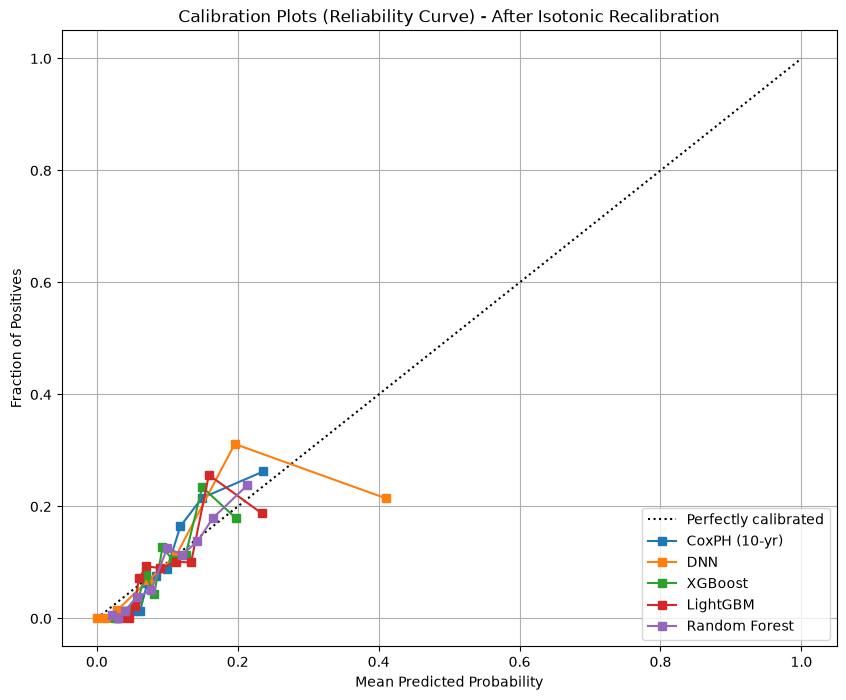

In [19]:
# Plot Calibration Curve
plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

for name, (y_t_true, preds_t) in test_models.items():
    prob_true, prob_pred = calibration_curve(y_t_true, preds_t, n_bins=10, strategy='quantile')
    plt.plot(prob_pred, prob_true, marker='s', label=name)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Plots (Reliability Curve) - After Isotonic Recalibration")
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('../results/calibration_plot.png')
plt.show()
